In [2]:

import pandas as pd
import numpy as np

# Make results reproducible
np.random.seed(42)

# Create 104 weeks of sample data
weeks = 104
dates = pd.date_range(
    start="2024-01-01",
    periods=weeks,
    freq="W"
)

# Generate weekly marketing spend in rupees
google_spend = np.random.uniform(5000, 15000, weeks)
meta_spend = np.random.uniform(4000, 12000, weeks)
tv_spend = np.random.uniform(0, 8000, weeks)

# Promotions: 1 means a promotion is running
promotion = np.random.choice(
    [0, 1], size=weeks, p=[0.75, 0.25]
)

# Calculate advertising carryover (adstock)
def calculate_adstock(spend, decay=0.5):
    result = []
    previous = 0

    for amount in spend:
        current = amount + decay * previous
        result.append(current)
        previous = current

    return np.array(result)

google_adstock = calculate_adstock(google_spend)
meta_adstock = calculate_adstock(meta_spend)
tv_adstock = calculate_adstock(tv_spend)

# Simple saturation: returns diminish as spend rises
google_effect = google_adstock / (
    google_adstock + 15000
)
meta_effect = meta_adstock / (
    meta_adstock + 12000
)
tv_effect = tv_adstock / (
    tv_adstock + 10000
)

# Generate synthetic sales revenue
seasonality = 8000 * np.sin(
    2 * np.pi * np.arange(weeks) / 52
)

noise = np.random.normal(0, 5000, weeks)

sales = (
    80000
    + 70000 * google_effect
    + 50000 * meta_effect
    + 30000 * tv_effect
    + 10000 * promotion
    + seasonality
    + noise
)

# Create the dataset
df = pd.DataFrame({
    "Date": dates,
    "Google_Spend": google_spend.round(2),
    "Meta_Spend": meta_spend.round(2),
    "TV_Spend": tv_spend.round(2),
    "Promotion": promotion,
    "Sales_Revenue": sales.round(2)
})

# Preview and save
print("Dataset created successfully!")
print("Number of weekly observations:", len(df))
display(df.head(10))

df.to_csv("mmm_marketing_data.csv", index=False)
print("CSV file saved successfully!")

Dataset created successfully!
Number of weekly observations: 104


,Date,Google_Spend,Meta_Spend,TV_Spend,Promotion,Sales_Revenue
0,2024-01-07,8745.40,11260.53,40.49,0,125077.05
1,2024-01-14,14507.14,5994.34,1286.46,1,151971.31
2,2024-01-21,12319.94,7283.06,4389.87,1,175289.99
3,2024-01-28,10986.58,10044.41,5535.16,0,170714.94
4,2024-02-04,6560.19,5830.39,5215.69,0,165969.71
5,2024-02-11,6559.95,4615.84,1794.15,0,159426.92
6,2024-02-18,5580.84,6318.01,5697.43,0,157349.43
7,2024-02-25,13661.76,5289.77,1897.99,0,157715.62
8,2024-03-03,11011.15,11437.58,2603.20,0,168301.50
9,2024-03-10,12080.73,10464.96,5971.93,0,170569.51


CSV file saved successfully!


In [3]:

# Check dataset size and column types
print("Dataset shape:", df.shape)

print("\nColumn information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nSummary statistics:")
display(df.describe().round(2))


Dataset shape: (104, 6)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           104 non-null    datetime64[ns]
 1   Google_Spend   104 non-null    float64       
 2   Meta_Spend     104 non-null    float64       
 3   TV_Spend       104 non-null    float64       
 4   Promotion      104 non-null    int64         
 5   Sales_Revenue  104 non-null    float64       
dtypes: datetime64[ns](1), float64(4), int64(1)
memory usage: 5.0 KB

Missing values:
Date             0
Google_Spend     0
Meta_Spend       0
TV_Spend         0
Promotion        0
Sales_Revenue    0
dtype: int64

Summary statistics:


,Date,Google_Spend,Meta_Spend,TV_Spend,Promotion,Sales_Revenue
count,104,104.00,104.00,104.00,104.00,104.00
mean,2025-01-01 12:00:00,9664.31,7958.41,4190.69,0.27,163405.37
min,2024-01-07 00:00:00,5055.22,4055.62,40.49,0.00,125077.05
25%,2024-07-05 06:00:00,6932.01,5912.65,2334.63,0.00,157592.17
50%,2025-01-01 12:00:00,9641.42,8053.70,4365.51,0.00,163266.64
75%,2025-06-30 18:00:00,12291.57,10129.47,6018.94,1.00,168897.07
max,2025-12-28 00:00:00,14868.87,11885.20,7920.43,1.00,186694.58
std,NaN,2956.96,2382.42,2290.61,0.45,9993.10


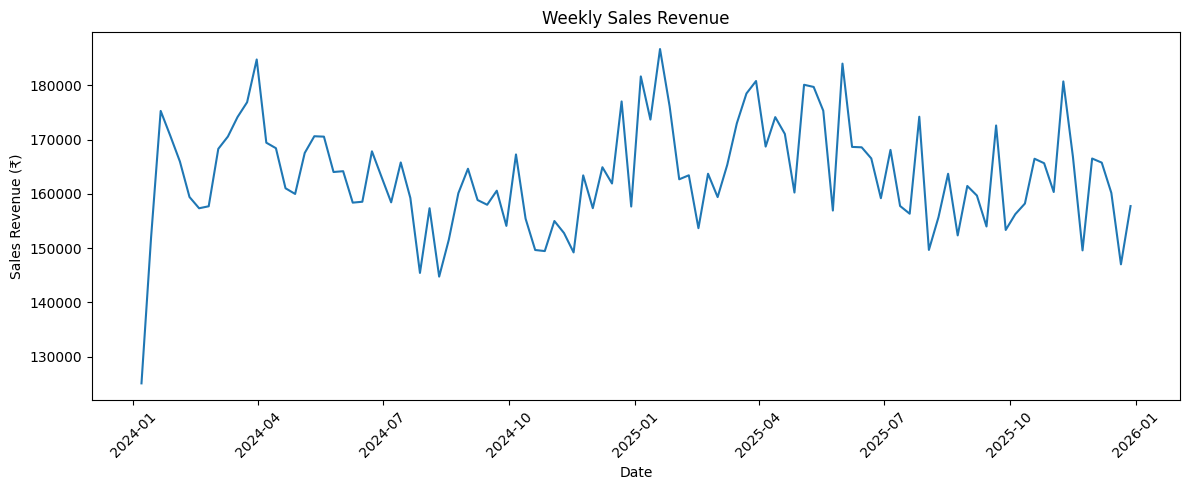

In [4]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Sales_Revenue"])
plt.title("Weekly Sales Revenue")
plt.xlabel("Date")
plt.ylabel("Sales Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


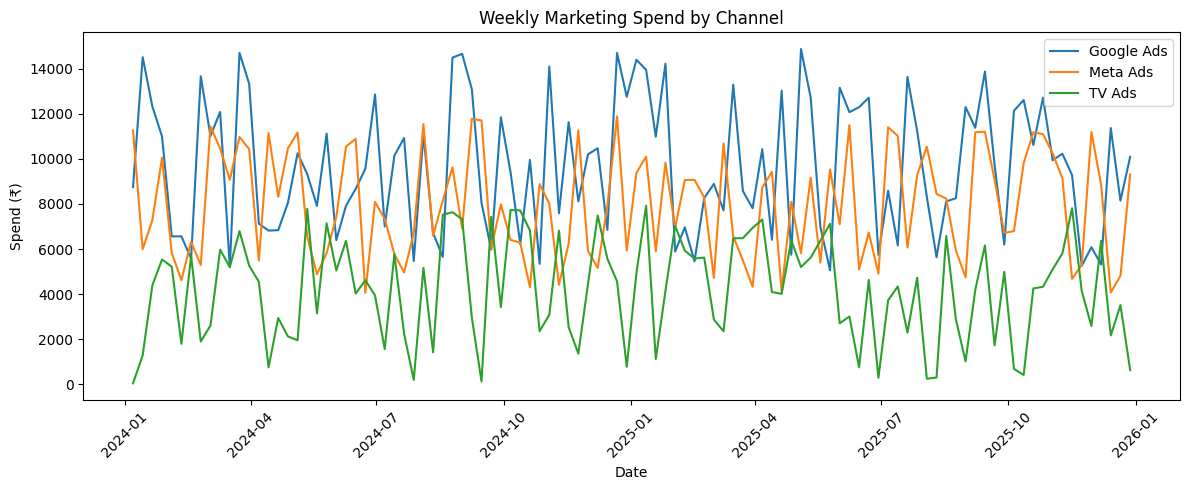

In [5]:

plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["Google_Spend"], label="Google Ads")
plt.plot(df["Date"], df["Meta_Spend"], label="Meta Ads")
plt.plot(df["Date"], df["TV_Spend"], label="TV Ads")

plt.title("Weekly Marketing Spend by Channel")
plt.xlabel("Date")
plt.ylabel("Spend (₹)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


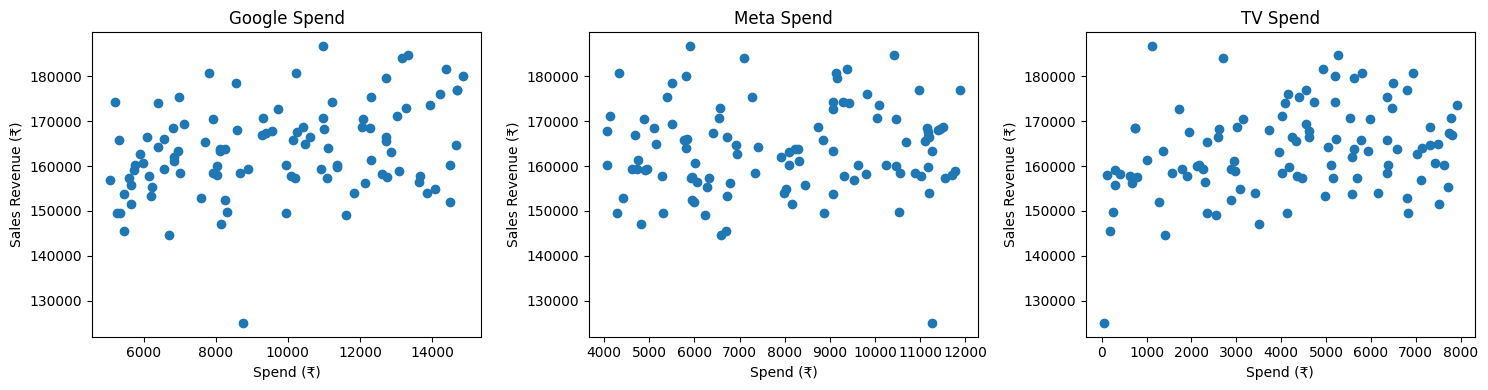

In [6]:

channels = ["Google_Spend", "Meta_Spend", "TV_Spend"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, channel in zip(axes, channels):
    ax.scatter(df[channel], df["Sales_Revenue"])
    ax.set_title(channel.replace("_", " "))
    ax.set_xlabel("Spend (₹)")
    ax.set_ylabel("Sales Revenue (₹)")

plt.tight_layout()
plt.show()


In [7]:

correlation = df[
    ["Google_Spend", "Meta_Spend", "TV_Spend", "Sales_Revenue"]
].corr()

display(correlation.round(2))


,Google_Spend,Meta_Spend,TV_Spend,Sales_Revenue
Google_Spend,1.00,0.09,-0.02,0.32
Meta_Spend,0.09,1.00,-0.08,0.06
TV_Spend,-0.02,-0.08,1.00,0.30
Sales_Revenue,0.32,0.06,0.30,1.00


In [8]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select the inputs and target
features = [
    "Google_Spend",
    "Meta_Spend",
    "TV_Spend",
    "Promotion"
]

X = df[features]
y = df["Sales_Revenue"]

# Split data into training and testing sets chronologically
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train the regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict sales for the test period
predictions = model.predict(X_test)

# Evaluate model performance
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("Model intercept:", round(model.intercept_, 2))
print("\nRegression coefficients:")
display(pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_.round(2)
}))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R-squared:", round(r2, 3))


Model intercept: 142780.82

Regression coefficients:


,Feature,Coefficient
0,Google_Spend,1.00
1,Meta_Spend,0.33
2,TV_Spend,1.54
3,Promotion,10972.51


MAE: 6142.89
RMSE: 7714.6
R-squared: -0.001


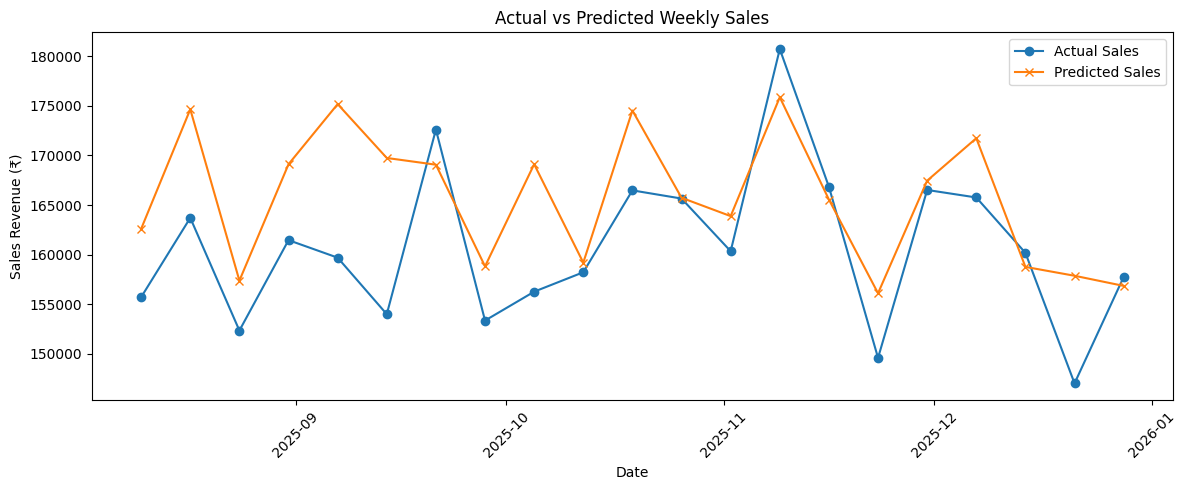

In [9]:

plt.figure(figsize=(12, 5))

plt.plot(
    df["Date"].iloc[split_index:],
    y_test,
    label="Actual Sales",
    marker="o"
)

plt.plot(
    df["Date"].iloc[split_index:],
    predictions,
    label="Predicted Sales",
    marker="x"
)

plt.title("Actual vs Predicted Weekly Sales")
plt.xlabel("Date")
plt.ylabel("Sales Revenue (₹)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [10]:

# Create a separate dataset for the improved model
df_mmm = df.copy()

# 1. Calculate adstock using past and current advertising spend
def calculate_adstock(spend, decay=0.5):
    result = []
    previous = 0

    for amount in spend:
        current = amount + decay * previous
        result.append(current)
        previous = current

    return np.array(result)

df_mmm["Google_Adstock"] = calculate_adstock(
    df_mmm["Google_Spend"]
)
df_mmm["Meta_Adstock"] = calculate_adstock(
    df_mmm["Meta_Spend"]
)
df_mmm["TV_Adstock"] = calculate_adstock(
    df_mmm["TV_Spend"]
)

# 2. Apply saturation
df_mmm["Google_Effect"] = (
    df_mmm["Google_Adstock"] /
    (df_mmm["Google_Adstock"] + 15000)
)

df_mmm["Meta_Effect"] = (
    df_mmm["Meta_Adstock"] /
    (df_mmm["Meta_Adstock"] + 12000)
)

df_mmm["TV_Effect"] = (
    df_mmm["TV_Adstock"] /
    (df_mmm["TV_Adstock"] + 10000)
)

# 3. Include seasonality
week_number = np.arange(len(df_mmm))

df_mmm["Seasonality"] = np.sin(
    2 * np.pi * week_number / 52
)

# 4. Select model features
features_mmm = [
    "Google_Effect",
    "Meta_Effect",
    "TV_Effect",
    "Promotion",
    "Seasonality"
]

X = df_mmm[features_mmm]
y = df_mmm["Sales_Revenue"]

# Maintain chronological train/test split
split_index = int(len(df_mmm) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train the improved regression model
mmm_model = LinearRegression()
mmm_model.fit(X_train, y_train)

predictions_mmm = mmm_model.predict(X_test)

# Evaluate
mae_mmm = mean_absolute_error(y_test, predictions_mmm)
rmse_mmm = np.sqrt(
    mean_squared_error(y_test, predictions_mmm)
)
r2_mmm = r2_score(y_test, predictions_mmm)

print("IMPROVED MMM BASELINE")
print("MAE:", round(mae_mmm, 2))
print("RMSE:", round(rmse_mmm, 2))
print("R-squared:", round(r2_mmm, 3))

print("\nModel coefficients:")
display(pd.DataFrame({
    "Feature": features_mmm,
    "Coefficient": mmm_model.coef_.round(2)
}))


IMPROVED MMM BASELINE
MAE: 4787.38
RMSE: 5538.71
R-squared: 0.484

Model coefficients:


,Feature,Coefficient
0,Google_Effect,100089.47
1,Meta_Effect,30365.01
2,TV_Effect,33143.86
3,Promotion,9190.51
4,Seasonality,7406.34


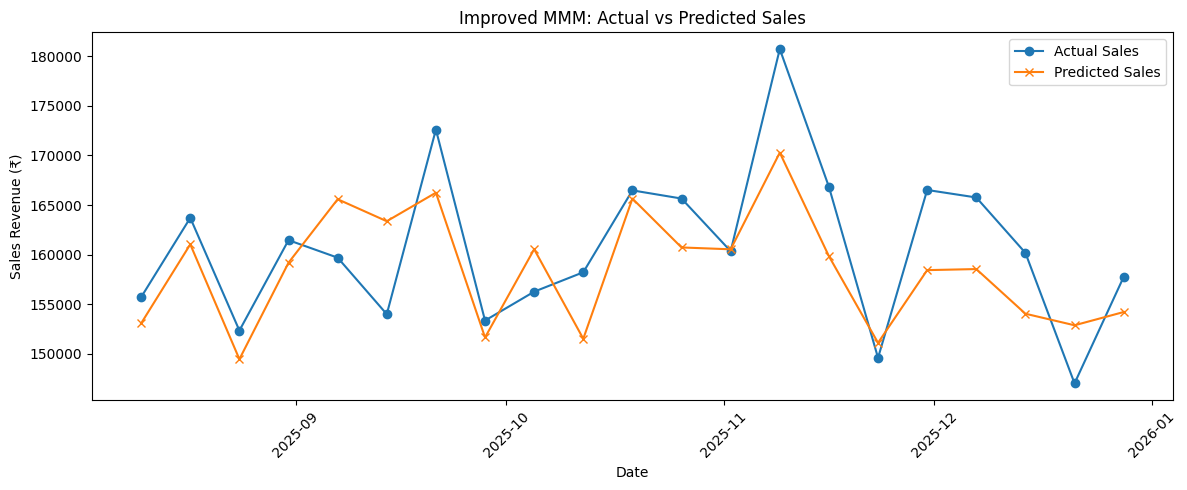

In [11]:

plt.figure(figsize=(12, 5))

plt.plot(
    df_mmm["Date"].iloc[split_index:],
    y_test,
    label="Actual Sales",
    marker="o"
)

plt.plot(
    df_mmm["Date"].iloc[split_index:],
    predictions_mmm,
    label="Predicted Sales",
    marker="x"
)

plt.title("Improved MMM: Actual vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Sales Revenue (₹)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,Channel,Estimated Contribution (₹),Share (%)
0,Google Ads,5788129.51,63.73
1,Meta Ads,1780219.88,19.60
2,TV Ads,1514548.34,16.67


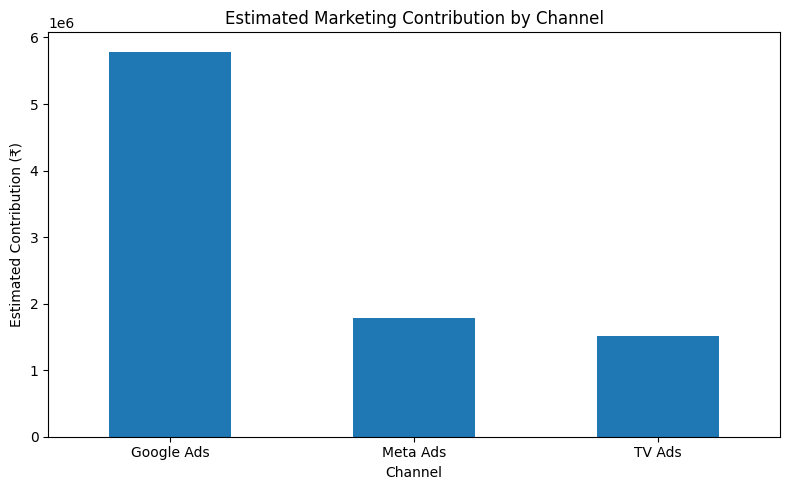

In [12]:

# Calculate each channel's contribution over the full dataset
contributions = pd.DataFrame({
    "Google Ads": (
        mmm_model.coef_[0] * df_mmm["Google_Effect"]
    ),
    "Meta Ads": (
        mmm_model.coef_[1] * df_mmm["Meta_Effect"]
    ),
    "TV Ads": (
        mmm_model.coef_[2] * df_mmm["TV_Effect"]
    )
})

# Sum estimated contributions across all weeks
total_contribution = contributions.sum()

summary = pd.DataFrame({
    "Channel": total_contribution.index,
    "Estimated Contribution (₹)": total_contribution.values
})

summary["Share (%)"] = (
    summary["Estimated Contribution (₹)"]
    / summary["Estimated Contribution (₹)"].sum()
    * 100
)

display(summary.round(2))

summary.plot(
    x="Channel",
    y="Estimated Contribution (₹)",
    kind="bar",
    legend=False,
    figsize=(8, 5)
)

plt.title("Estimated Marketing Contribution by Channel")
plt.ylabel("Estimated Contribution (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [13]:

# Total advertising spend over the complete dataset
total_spend = {
    "Google Ads": df_mmm["Google_Spend"].sum(),
    "Meta Ads": df_mmm["Meta_Spend"].sum(),
    "TV Ads": df_mmm["TV_Spend"].sum()
}

# Combine spend and contribution estimates
roas_table = summary.copy()

roas_table["Total Spend (₹)"] = (
    roas_table["Channel"].map(total_spend)
)

roas_table["Preliminary ROAS"] = (
    roas_table["Estimated Contribution (₹)"]
    / roas_table["Total Spend (₹)"]
)

display(roas_table.round(2))


,Channel,Estimated Contribution (₹),Share (%),Total Spend (₹),Preliminary ROAS
0,Google Ads,5788129.51,63.73,1005088.38,5.76
1,Meta Ads,1780219.88,19.60,827674.85,2.15
2,TV Ads,1514548.34,16.67,435831.41,3.48


In [14]:

# Review the fitted model coefficients
coefficient_check = pd.DataFrame({
    "Feature": ["Intercept"] + features_mmm,
    "Coefficient": [
        mmm_model.intercept_,
        *mmm_model.coef_
    ]
})

display(coefficient_check.round(2))

# Check whether channel contributions are positive
print("\nChannel contribution totals:")
display(contributions.sum().round(2))

# Check total observed revenue
print("\nTotal observed sales revenue:")
print(round(df_mmm["Sales_Revenue"].sum(), 2))

# Check total fitted revenue over the full dataset
full_predictions = mmm_model.predict(
    df_mmm[features_mmm]
)

print("\nTotal model-predicted sales:")
print(round(full_predictions.sum(), 2))


,Feature,Coefficient
0,Intercept,73150.19
1,Google_Effect,100089.47
2,Meta_Effect,30365.01
3,TV_Effect,33143.86
4,Promotion,9190.51
5,Seasonality,7406.34



Channel contribution totals:


,0
Google Ads,5788129.51
Meta Ads,1780219.88
TV Ads,1514548.34



Total observed sales revenue:
16994158.3

Total model-predicted sales:
16947851.52


In [15]:

# Decompose fitted sales using the model's coefficients
decomposition = pd.DataFrame({
    "Baseline": np.repeat(
        mmm_model.intercept_, len(df_mmm)
    ),
    "Google Ads": (
        mmm_model.coef_[0] * df_mmm["Google_Effect"]
    ),
    "Meta Ads": (
        mmm_model.coef_[1] * df_mmm["Meta_Effect"]
    ),
    "TV Ads": (
        mmm_model.coef_[2] * df_mmm["TV_Effect"]
    ),
    "Promotions": (
        mmm_model.coef_[3] * df_mmm["Promotion"]
    ),
    "Seasonality": (
        mmm_model.coef_[4] * df_mmm["Seasonality"]
    )
})

# Sum each component over all 104 weeks
decomposition_summary = decomposition.sum().to_frame(
    name="Estimated Sales Contribution (₹)"
)

decomposition_summary["Share of Fitted Sales (%)"] = (
    decomposition_summary["Estimated Sales Contribution (₹)"]
    / decomposition_summary["Estimated Sales Contribution (₹)"].sum()
    * 100
)

display(decomposition_summary.round(2))

print(
    "Total decomposed sales:",
    round(decomposition.sum(axis=1).sum(), 2)
)


,Estimated Sales Contribution (₹),Share of Fitted Sales (%)
Baseline,7607619.41,44.89
Google Ads,5788129.51,34.15
Meta Ads,1780219.88,10.50
TV Ads,1514548.34,8.94
Promotions,257334.37,1.52
Seasonality,-0.00,-0.00


Total decomposed sales: 16947851.52


In [16]:

from google.colab import files
files.download("mmm_marketing_data.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>